# Model training - credit default (30dpd_6mob)

Trains on the **gold feature store** + **gold label store** built by `main.py` / `data_processing_main.ipynb`.
All logic lives in `utils/model_train.py`; `model_train.py` is the same thing as a CLI:

```
python model_train.py --model_train_date 2024-09-01 --train_test_months 12 --oot_months 2
```

**Point-in-time rules**
* label store `snapshot_date` = date the label is *known* (loan_start_date + 6 mob) → train / test / OOT windows are cut on it
* features are joined on the *application* date: `label.loan_start_date == feature_store.snapshot_date`

In [1]:
import os
import glob
import pprint
import pickle
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pyspark
import pyspark.sql.functions as F
from pyspark.sql.functions import col

from sklearn.metrics import roc_auc_score

import utils.model_train as mt

## set up pyspark session

In [9]:
spark = pyspark.sql.SparkSession.builder \
    .appName("model_train") \
    .master("local[*]") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

ERROR StatusConsoleListener Could not determine local host name
 java.net.UnknownHostException: claude: claude: Temporary failure in name resolution
	at java.base/java.net.InetAddress.getLocalHost(InetAddress.java:1670)
	at org.apache.logging.log4j.core.util.NetUtils.getLocalHostname(NetUtils.java:56)
	at org.apache.logging.log4j.core.LoggerContext.lambda$setConfiguration$0(LoggerContext.java:615)
	at java.base/java.util.concurrent.ConcurrentHashMap.computeIfAbsent(ConcurrentHashMap.java:1705)
	at org.apache.logging.log4j.core.LoggerContext.setConfiguration(LoggerContext.java:615)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:694)
	at org.apache.logging.log4j.core.LoggerContext.reconfigure(LoggerContext.java:711)
	at org.apache.spark.internal.Logging$.uninitialize(Logging.scala:220)
	at org.apache.spark.deploy.SparkSubmit.org$apache$spark$deploy$SparkSubmit$$runMain(SparkSubmit.scala:972)
	at org.apache.spark.deploy.SparkSubmit.doRunMain$1(SparkSubmit.s

## set up config
Windows are on the **label** snapshot_date: 12 months train/test, then 2 months OOT, ending the day before `model_train_date`.

In [10]:
model_train_date_str = "2024-09-01"
train_test_period_months = 12
oot_period_months = 2
train_test_ratio = 0.8

config = mt.build_config(model_train_date_str, train_test_period_months, oot_period_months, train_test_ratio)
pprint.pprint(config)

{'model_train_date': datetime.datetime(2024, 9, 1, 0, 0),
 'model_train_date_str': '2024-09-01',
 'oot_end_date': datetime.datetime(2024, 8, 31, 0, 0),
 'oot_period_months': 2,
 'oot_start_date': datetime.datetime(2024, 7, 1, 0, 0),
 'train_test_end_date': datetime.datetime(2024, 6, 30, 0, 0),
 'train_test_period_months': 12,
 'train_test_ratio': 0.8,
 'train_test_start_date': datetime.datetime(2023, 7, 1, 0, 0)}


## get label store

In [11]:
label_store_sdf = mt.read_store(spark, mt.LABEL_STORE_DIR)
print("row_count:", label_store_sdf.count())
label_store_sdf.show(5)

# bad rate by month the label became known
label_store_sdf.groupBy("snapshot_date").agg(F.count("*").alias("n"), F.round(F.avg("label"), 3).alias("bad_rate")) \
    .orderBy("snapshot_date").show(30)

row_count: 12500
+--------------------+-----------+---------------+-----+----------+-------------+
|             loan_id|Customer_ID|loan_start_date|label| label_def|snapshot_date|
+--------------------+-----------+---------------+-----+----------+-------------+
|CUS_0x10ac_2024_0...| CUS_0x10ac|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
|CUS_0x10c5_2024_0...| CUS_0x10c5|     2024-08-01|    1|30dpd_6mob|   2025-02-01|
|CUS_0x1145_2024_0...| CUS_0x1145|     2024-08-01|    1|30dpd_6mob|   2025-02-01|
|CUS_0x11ac_2024_0...| CUS_0x11ac|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
|CUS_0x122c_2024_0...| CUS_0x122c|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
+--------------------+-----------+---------------+-----+----------+-------------+
only showing top 5 rows



[Stage 6:===>                                                     (1 + 17) / 18]

+-------------+---+--------+
|snapshot_date|  n|bad_rate|
+-------------+---+--------+
|   2023-07-01|530|   0.264|
|   2023-08-01|501|   0.307|
|   2023-09-01|506|    0.32|
|   2023-10-01|510|   0.269|
|   2023-11-01|521|   0.267|
|   2023-12-01|517|   0.265|
|   2024-01-01|471|   0.297|
|   2024-02-01|481|   0.289|
|   2024-03-01|454|   0.262|
|   2024-04-01|487|   0.257|
|   2024-05-01|491|   0.291|
|   2024-06-01|489|   0.309|
|   2024-07-01|485|   0.297|
|   2024-08-01|518|   0.284|
|   2024-09-01|511|   0.329|
|   2024-10-01|513|   0.277|
|   2024-11-01|491|   0.303|
|   2024-12-01|498|   0.311|
|   2025-01-01|505|   0.307|
|   2025-02-01|543|     0.3|
|   2025-03-01|493|   0.331|
|   2025-04-01|456|   0.246|
|   2025-05-01|488|   0.281|
|   2025-06-01|515|   0.272|
|   2025-07-01|526|   0.268|
+-------------+---+--------+



+--------------------+-----------+---------------+-----+----------+-------------+
|             loan_id|Customer_ID|loan_start_date|label| label_def|snapshot_date|
+--------------------+-----------+---------------+-----+----------+-------------+
|CUS_0x10ac_2024_0...| CUS_0x10ac|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
|CUS_0x10c5_2024_0...| CUS_0x10c5|     2024-08-01|    1|30dpd_6mob|   2025-02-01|
|CUS_0x1145_2024_0...| CUS_0x1145|     2024-08-01|    1|30dpd_6mob|   2025-02-01|
|CUS_0x11ac_2024_0...| CUS_0x11ac|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
|CUS_0x122c_2024_0...| CUS_0x122c|     2024-08-01|    0|30dpd_6mob|   2025-02-01|
+--------------------+-----------+---------------+-----+----------+-------------+
only showing top 5 rows



+-------------+---+--------+
|snapshot_date|  n|bad_rate|
+-------------+---+--------+
|   2023-07-01|530|   0.264|
|   2023-08-01|501|   0.307|
|   2023-09-01|506|    0.32|
|   2023-10-01|510|   0.269|
|   2023-11-01|521|   0.267|
|   2023-12-01|517|   0.265|
|   2024-01-01|471|   0.297|
|   2024-02-01|481|   0.289|
|   2024-03-01|454|   0.262|
|   2024-04-01|487|   0.257|
|   2024-05-01|491|   0.291|
|   2024-06-01|489|   0.309|
|   2024-07-01|485|   0.297|
|   2024-08-01|518|   0.284|
|   2024-09-01|511|   0.329|
|   2024-10-01|513|   0.277|
|   2024-11-01|491|   0.303|
|   2024-12-01|498|   0.311|
|   2025-01-01|505|   0.307|
|   2025-02-01|543|     0.3|
|   2025-03-01|493|   0.331|
|   2025-04-01|456|   0.246|
|   2025-05-01|488|   0.281|
|   2025-06-01|515|   0.272|
|   2025-07-01|526|   0.268|
+-------------+---+--------+



## get features

In [12]:
features_store_sdf = mt.read_store(spark, mt.FEATURE_STORE_DIR)
print("row_count:", features_store_sdf.count(), "| columns:", len(features_store_sdf.columns))
features_store_sdf.printSchema()

row_count: 12500 | columns: 61
root
 |-- Customer_ID: string (nullable = true)
 |-- snapshot_date: date (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Occupation: string (nullable = true)
 |-- Annual_Income: decimal(10,2) (nullable = true)
 |-- Monthly_Inhand_Salary: decimal(10,2) (nullable = true)
 |-- Num_Bank_Accounts: integer (nullable = true)
 |-- Num_Credit_Card: integer (nullable = true)
 |-- Interest_Rate: integer (nullable = true)
 |-- Num_of_Loan: integer (nullable = true)
 |-- Delay_from_due_date: integer (nullable = true)
 |-- Num_of_Delayed_Payment: integer (nullable = true)
 |-- Changed_Credit_Limit: decimal(10,2) (nullable = true)
 |-- Num_Credit_Inquiries: integer (nullable = true)
 |-- Credit_Mix: string (nullable = true)
 |-- Outstanding_Debt: decimal(10,2) (nullable = true)
 |-- Credit_Utilization_Ratio: decimal(10,2) (nullable = true)
 |-- Payment_of_Min_Amount: string (nullable = true)
 |-- Total_EMI_per_month: decimal(10,2) (nullable = true)
 |-- Amoun

**Known gap:** the clickstream file ends before the later application months, so `fe_1..fe_20` are entirely null
for applications from **2024-07** onwards (= labels known from **2025-01**).

In [13]:
features_store_sdf.groupBy("snapshot_date") \
    .agg(F.round(F.avg(F.col("fe_1").isNull().cast("int")), 2).alias("clickstream_missing")) \
    .orderBy("snapshot_date").show(30)

+-------------+-------------------+
|snapshot_date|clickstream_missing|
+-------------+-------------------+
|   2023-01-01|                0.0|
|   2023-02-01|                0.0|
|   2023-03-01|                0.0|
|   2023-04-01|                0.0|
|   2023-05-01|                0.0|
|   2023-06-01|                0.0|
|   2023-07-01|                0.0|
|   2023-08-01|                0.0|
|   2023-09-01|                0.0|
|   2023-10-01|                0.0|
|   2023-11-01|                0.0|
|   2023-12-01|                0.0|
|   2024-01-01|                0.0|
|   2024-02-01|                0.0|
|   2024-03-01|                0.0|
|   2024-04-01|                0.0|
|   2024-05-01|                0.0|
|   2024-06-01|                0.0|
|   2024-07-01|                1.0|
|   2024-08-01|                1.0|
|   2024-09-01|                1.0|
|   2024-10-01|                1.0|
|   2024-11-01|                1.0|
|   2024-12-01|                1.0|
|   2025-01-01|             

## prepare data for modeling
Join labels known in the window to the features captured at application.

In [14]:
data_pdf = mt.load_training_data(spark, config)
data_pdf.head()

labels in window: 6961 | labels without features: 0 | 2023-07-01 -> 2024-08-31


,loan_id,Customer_ID,loan_start_date,label,label_def,label_snapshot_date,feature_snapshot_date,Age,Occupation,Annual_Income,...,n_Student_Loan,Total_Loans,n_secured,n_unsecured,n_distinct_loan_types,debt_to_income,emi_to_income,Spend_Level,Payment_Value,Credit_Mix_MinAmt
0,CUS_0x1037_2023_01_01,CUS_0x1037,2023-01-01,0,30dpd_6mob,2023-07-01,2023-01-01,45.0,Accountant,15989.09,...,0,4,3,1,3,0.041642,0.031111,Low,Small,Good_No
1,CUS_0x1069_2023_01_01,CUS_0x1069,2023-01-01,0,30dpd_6mob,2023-07-01,2023-01-01,32.0,Accountant,58637.34,...,0,3,1,1,3,0.003561,0.029147,High,Small,Standard_Yes
2,CUS_0x114a_2023_01_01,CUS_0x114a,2023-01-01,0,30dpd_6mob,2023-07-01,2023-01-01,43.0,Developer,15305.46,...,1,2,1,1,2,0.041973,0.016498,Low,Small,Good_No
3,CUS_0x1184_2023_01_01,CUS_0x1184,2023-01-01,0,30dpd_6mob,2023-07-01,2023-01-01,49.0,Lawyer,19867.48,...,1,3,1,2,3,0.035600,0.030509,Unknown,Unknown,Good_No
4,CUS_0x1297_2023_01_01,CUS_0x1297,2023-01-01,1,30dpd_6mob,2023-07-01,2023-01-01,46.0,Manager,57738.06,...,1,9,2,7,6,0.067832,0.060694,High,Medium,Bad_Yes


In [15]:
feature_cols, numeric_cols, categorical_cols = mt.get_feature_columns(data_pdf)
print(len(feature_cols), "features")
print("categorical:", categorical_cols)
print("dropped as redundant:", mt.REDUNDANT_COLS)

57 features
categorical: ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Spend_Level', 'Payment_Value']
dropped as redundant: ['Payment_Behaviour', 'Credit_Mix_MinAmt']


## split data into train - test - oot

In [17]:
splits = mt.split_data(data_pdf, config, feature_cols)
X_train, y_train = splits["train"]
X_test, y_test = splits["test"]
X_oot, y_oot = splits["oot"]

train rows= 4766  bad_rate=0.283  clickstream_missing=0.0%
test  rows= 1192  bad_rate=0.283  clickstream_missing=0.0%
oot   rows= 1003  bad_rate=0.290  clickstream_missing=0.0%


## preprocess data
One `ColumnTransformer` per model type, **fitted on train only** and pickled inside the model pipeline:

| step | logistic regression | XGBoost |
|---|---|---|
| numerics (Age, Num_of_Loan, ...) | median impute + missing flag, then scale | median impute + missing flag |
| clickstream `fe_*` | median impute + missing flag, then scale | passthrough - NaN handled natively |
| categoricals | `'_'`/null → `Unknown`, one-hot (`handle_unknown='ignore'`) | same |

In [18]:
preview = mt.build_preprocessor(numeric_cols, categorical_cols, "logreg").fit(X_train)
X_train_processed = pd.DataFrame(preview.transform(X_train), columns=preview.get_feature_names_out())
print("processed shape:", X_train_processed.shape)
X_train_processed.head()

processed shape: (4766, 83)


,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,...,Credit_Mix_Unknown,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Spend_Level_High,Spend_Level_Low,Spend_Level_Unknown,Payment_Value_Large,Payment_Value_Medium,Payment_Value_Small,Payment_Value_Unknown
0,-1.111913,-0.089532,0.007524,-0.121809,-0.129057,-0.124964,-0.003682,-0.664871,-0.071294,0.131424,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.870998,-0.067585,0.711366,-0.078235,-0.143828,-0.120729,0.010916,1.409986,-0.027868,-0.341608,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,-0.167670,-0.114051,-0.989154,-0.060806,-0.143828,-0.103788,0.040112,-0.129424,-0.067346,-0.186372,...,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,0.021179,-0.060232,0.948919,-0.086950,-0.158600,-0.137669,-0.032877,0.673746,-0.079189,-0.293280,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,-1.111913,-0.112797,-0.828261,-0.095665,-0.114285,-0.114376,0.083906,1.075331,-0.035764,-1.054818,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## train models
Both candidates are tuned with `RandomizedSearchCV(scoring="roc_auc")` on train (3-fold CV, 20 iterations).

> The reference notebook used `make_scorer(roc_auc_score)`, which scores **hard 0/1 predictions** instead of
> probabilities - that's why its CV AUC was ~0.52. `scoring="roc_auc"` uses `predict_proba`.

The winner is chosen on **test AUC**; OOT is reported only, never used to choose.

In [19]:
best_name, candidates = mt.train_and_select(splits, numeric_cols, categorical_cols, n_iter=20, cv=3)
best_model = candidates[best_name]["model"]

logreg   cv_auc=0.7704  gini train/test/oot = 0.571 / 0.597 / 0.550
xgboost  cv_auc=0.8130  gini train/test/oot = 0.957 / 0.692 / 0.667
selected (highest test AUC): xgboost


xgboost  cv_auc=0.8130  gini train/test/oot = 0.957 / 0.692 / 0.667
selected (highest test AUC): xgboost


In [20]:
comparison = pd.DataFrame({n: c["results"] for n, c in candidates.items()}).T
comparison[["cv_auc", "auc_train", "auc_test", "auc_oot", "gini_train", "gini_test", "gini_oot"]]

,cv_auc,auc_train,auc_test,auc_oot,gini_train,gini_test,gini_oot
logreg,0.7704,0.7856,0.7987,0.7748,0.571,0.597,0.550
xgboost,0.8130,0.9787,0.8458,0.8334,0.957,0.692,0.667


In [21]:
print("best params:")
pprint.pprint(candidates[best_name]["best_params"])

best params:
{'colsample_bytree': 1.0,
 'gamma': 0.1,
 'learning_rate': 0.03,
 'max_depth': 5,
 'min_child_weight': 1,
 'n_estimators': 300,
 'reg_alpha': 0.1,
 'reg_lambda': 1.5,
 'scale_pos_weight': 2.53,
 'subsample': 0.6}


### feature importance (winning model)

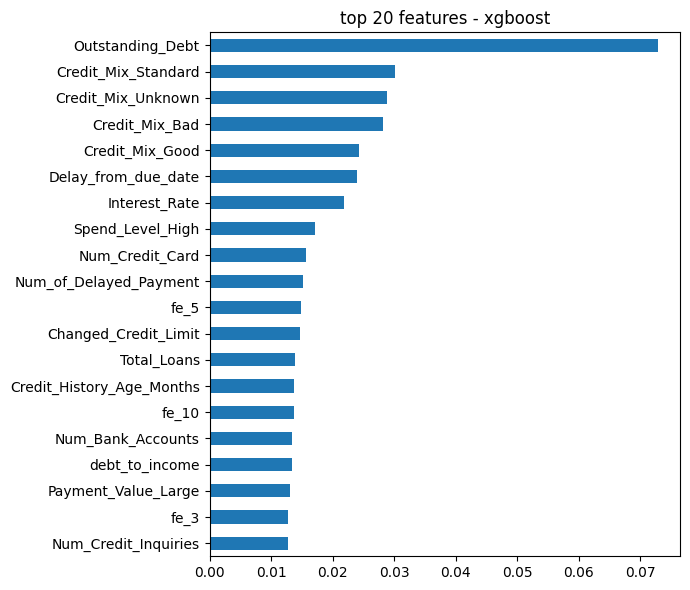

In [22]:
model_step = best_model.named_steps["model"]
names = best_model.named_steps["preprocess"].get_feature_names_out()
if hasattr(model_step, "feature_importances_"):
    imp = pd.Series(model_step.feature_importances_, index=names)
else:
    imp = pd.Series(np.abs(model_step.coef_[0]), index=names)
imp.sort_values().tail(20).plot(kind="barh", figsize=(7, 6), title=f"top 20 features - {best_name}")
plt.tight_layout()
plt.show()

## prepare model artefact to save

In [23]:
label_def = data_pdf["label_def"].iloc[0]
model_artefact = mt.build_artefact(config, best_name, candidates, splits,
                                   feature_cols, numeric_cols, categorical_cols, label_def)
pprint.pprint({k: v for k, v in model_artefact.items() if k not in ("model", "feature_cols", "numeric_cols")})

{'candidates': {'logreg': {'hp_params': {'C': 0.01, 'class_weight': 'balanced'},
                           'results': {'auc_oot': 0.7748,
                                       'auc_test': 0.7987,
                                       'auc_train': 0.7856,
                                       'cv_auc': 0.7704,
                                       'gini_oot': 0.55,
                                       'gini_test': 0.597,
                                       'gini_train': 0.571}},
                'xgboost': {'hp_params': {'colsample_bytree': 1.0,
                                          'gamma': 0.1,
                                          'learning_rate': 0.03,
                                          'max_depth': 5,
                                          'min_child_weight': 1,
                                          'n_estimators': 300,
                                          'reg_alpha': 0.1,
                                          'reg_lambda': 1.5,
            

## save artefact to model bank
`.pkl` holds everything (incl. the fitted pipeline); `.json` holds the metadata/metrics for monitoring.

In [25]:
pkl_path, json_path = mt.save_artefact(model_artefact)

model saved to model_bank/credit_model_2024_09_01.pkl
metrics saved to model_bank/credit_model_2024_09_01.json


## test load pickle and make model inference
The pickled pipeline takes raw gold-store columns - no manual preprocessing needed.

In [26]:
loaded_model_artefact = mt.load_artefact(pkl_path)

y_pred_proba = loaded_model_artefact["model"].predict_proba(X_oot[loaded_model_artefact["feature_cols"]])[:, 1]
oot_auc_score = roc_auc_score(y_oot, y_pred_proba)
print("OOT AUC score: ", round(oot_auc_score, 4), "| GINI:", round(2 * oot_auc_score - 1, 3))
print("Model loaded successfully!")

OOT AUC score:  0.8334 | GINI: 0.667
Model loaded successfully!


## caveat: this model never saw missing clickstream

Train / test / OOT for 2024-09-01 contain **0% missing clickstream**. XGBoost only learns where to route NaN from
NaNs seen in training, so for applications from 2024-07 (labels from 2025-01) it falls back to a default branch.
Preview: score every later label month with this model.

In [27]:
later_config = mt.build_config("2025-08-01", train_test_months=0, oot_months=11)   # labels 2024-09 .. 2025-07
later_pdf = mt.load_training_data(spark, later_config)

def gini_by_month(artefact, df):
    df = df.copy()
    df["score"] = artefact["model"].predict_proba(df[artefact["feature_cols"]])[:, 1]
    out = df.groupby("label_snapshot_date").apply(
        lambda g: pd.Series({"n": len(g),
                             "clickstream_missing": g["fe_1"].isna().mean(),
                             "gini": 2 * roc_auc_score(g["label"], g["score"]) - 1}))
    return out.round(3)

gini_2024_09 = gini_by_month(loaded_model_artefact, later_pdf)
gini_2024_09

labels in window: 5539 | labels without features: 0 | 2024-09-01 -> 2025-07-31


/tmp/ipykernel_20/3759066689.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = df.groupby("label_snapshot_date").apply(


,n,clickstream_missing,gini
label_snapshot_date,,,
2024-09-01,511.0,0.0,0.621
2024-10-01,513.0,0.0,0.601
2024-11-01,491.0,0.0,0.609
2024-12-01,498.0,0.0,0.670
2025-01-01,505.0,1.0,0.565
2025-02-01,543.0,1.0,0.429
2025-03-01,493.0,1.0,0.537
2025-04-01,456.0,1.0,0.527
2025-05-01,488.0,1.0,0.560


## retrain: model_train_date = 2025-04-01

Same code, later date. The train window now includes the first month with missing clickstream (~8% of rows), and
the OOT months are 100% missing, so the model learns a NaN route and the OOT score is measured on missing clickstream.

In [19]:
model_artefact_2025_04 = mt.run_training(spark, "2025-04-01", train_test_months=12, oot_months=2)

{'model_train_date': datetime.datetime(2025, 4, 1, 0, 0),
 'model_train_date_str': '2025-04-01',
 'oot_end_date': datetime.datetime(2025, 3, 31, 0, 0),
 'oot_period_months': 2,
 'oot_start_date': datetime.datetime(2025, 2, 1, 0, 0),
 'train_test_end_date': datetime.datetime(2025, 1, 31, 0, 0),
 'train_test_period_months': 12,
 'train_test_ratio': 0.8,
 'train_test_start_date': datetime.datetime(2024, 2, 1, 0, 0)}


labels in window: 6959 | labels without features: 0 | 2024-02-01 -> 2025-03-31
train rows= 4738  bad_rate=0.293  clickstream_missing=8.6%
test  rows= 1185  bad_rate=0.294  clickstream_missing=8.1%
oot   rows= 1036  bad_rate=0.315  clickstream_missing=100.0%


logreg   cv_auc=0.7634  gini train/test/oot = 0.569 / 0.539 / 0.495


xgboost  cv_auc=0.8032  gini train/test/oot = 0.832 / 0.645 / 0.600
selected (highest test AUC): xgboost
model saved to model_bank/credit_model_2025_04_01.pkl
metrics saved to model_bank/credit_model_2025_04_01.json


In [20]:
summary = pd.DataFrame({a["model_version"]: {**a["results"], **{k: v for k, v in a["data_stats"].items() if "clickstream" in k}}
                        for a in [loaded_model_artefact, model_artefact_2025_04]}).T
summary

,auc_train,gini_train,auc_test,gini_test,auc_oot,gini_oot,cv_auc,clickstream_missing_train,clickstream_missing_test,clickstream_missing_oot
credit_model_2024_09_01,0.9787,0.957,0.8458,0.692,0.8334,0.667,0.8130,0.000,0.000,0.0
credit_model_2025_04_01,0.9158,0.832,0.8226,0.645,0.8002,0.600,0.8032,0.086,0.081,1.0


In [21]:
# label months after 2025-04-01 are out-of-time for both models
after = later_pdf[pd.to_datetime(later_pdf["label_snapshot_date"]) >= "2025-04-01"]
pd.concat({"credit_model_2024_09_01": gini_by_month(loaded_model_artefact, after)["gini"],
           "credit_model_2025_04_01": gini_by_month(model_artefact_2025_04, after)["gini"]}, axis=1)

,credit_model_2024_09_01,credit_model_2025_04_01
label_snapshot_date,,
2025-04-01,0.527,0.616
2025-05-01,0.560,0.607
2025-06-01,0.623,0.683
2025-07-01,0.519,0.547


In [22]:
spark.stop()